# Módulo 6 — Integración directa (prototipo en Python)

**Proyecto:** Cálculo Integral Interactivo · Matemáticas II · UTP

Objetivo: **verificar por derivación** las antiderivadas de las fórmulas básicas y de los ejemplos del módulo 6. La verificación se hace derivando el resultado con SymPy y comprobando que se obtiene $f(x)$. También comparamos con lo que devuelve `sp.integrate`.

## 1. Preparación

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Con positive=True le decimos a SymPy que x > 0; así ln|x| se escribe simplemente log(x)
# y las raíces como √x no dan problemas. (Es la misma condición x > 0 de los ejemplos.)
x = sp.symbols("x", positive=True)

def verificar(f, F):
    """Devuelve True si F'(x) = f(x): esa es la definición de antiderivada."""
    return sp.simplify(sp.diff(F, x) - f) == 0

## 2. Tabla de fórmulas básicas, verificadas por derivación
Cada fila es `(f, F)`. Si `verificar` da `True`, entonces $F$ es una antiderivada de $f$.

In [2]:
k = 7                      # una constante cualquiera
a_base = 2                 # base para a^x
tabla = [
    ("k",             sp.Integer(k),              k * x),
    ("x^n (n=5)",     x**5,                       x**6 / 6),
    ("1/x",           1 / x,                      sp.log(x)),
    ("e^x",           sp.exp(x),                  sp.exp(x)),
    ("a^x (a=2)",     a_base**x,                  a_base**x / sp.log(a_base)),
    ("sen x",         sp.sin(x),                  -sp.cos(x)),
    ("cos x",         sp.cos(x),                  sp.sin(x)),
    ("sec² x",        sp.sec(x)**2,               sp.tan(x)),
    ("csc² x",        sp.csc(x)**2,               -sp.cot(x)),
    ("sec x · tan x", sp.sec(x) * sp.tan(x),      sp.sec(x)),
    ("csc x · cot x", sp.csc(x) * sp.cot(x),      -sp.csc(x)),
]

print(f"{'función':<16} {'antiderivada':<22} ¿F' = f?")
print("-" * 50)
for nombre, f, F in tabla:
    ok = verificar(f, F)
    print(f"{nombre:<16} {str(F):<22} {'✔' if ok else '✘'}")
    assert ok, f"Falló la verificación de {nombre}"

función          antiderivada           ¿F' = f?
--------------------------------------------------
k                7*x                    ✔
x^n (n=5)        x**6/6                 ✔
1/x              log(x)                 ✔
e^x              exp(x)                 ✔
a^x (a=2)        2**x/log(2)            ✔
sen x            -cos(x)                ✔
cos x            sin(x)                 ✔
sec² x           tan(x)                 ✔
csc² x           -cot(x)                ✔
sec x · tan x    sec(x)                 ✔
csc x · cot x    -csc(x)                ✔


## 3. Los cuatro ejemplos del módulo 6
Guardamos **nuestra** respuesta hecha a mano, la verificamos por derivación y la comparamos con SymPy (que puede escribirla distinto pero equivalente salvo constante).

In [3]:
ejemplos = [
    ("Ej. 1  ∫(3x² − 4x + 5) dx",      3 * x**2 - 4 * x + 5,
        x**3 - 2 * x**2 + 5 * x),
    ("Ej. 2  ∫(√x + 3/x) dx",           sp.sqrt(x) + 3 / x,
        sp.Rational(2, 3) * x**sp.Rational(3, 2) + 3 * sp.log(x)),
    ("Ej. 3  ∫(2 sen x − 5 cos x + eˣ) dx", 2 * sp.sin(x) - 5 * sp.cos(x) + sp.exp(x),
        -2 * sp.cos(x) - 5 * sp.sin(x) + sp.exp(x)),
    ("Ej. 4  ∫(x² − 1)/√x dx",          (x**2 - 1) / sp.sqrt(x),
        sp.Rational(2, 5) * x**sp.Rational(5, 2) - 2 * sp.sqrt(x)),
]

for titulo, f, F_mano in ejemplos:
    F_sympy = sp.integrate(f, x)
    print(titulo)
    print("   a mano :", F_mano, "+ C")
    print("   SymPy  :", F_sympy, "+ C")
    print("   ¿F_mano' = f ?                  ", verificar(f, F_mano))
    print("   ¿F_mano − F_SymPy es constante? ", sp.simplify(sp.diff(F_mano - F_sympy, x)) == 0)
    print()
    assert verificar(f, F_mano)
print("✔ Los cuatro ejemplos están verificados")

Ej. 1  ∫(3x² − 4x + 5) dx
   a mano : x**3 - 2*x**2 + 5*x + C
   SymPy  : x**3 - 2*x**2 + 5*x + C
   ¿F_mano' = f ?                   True
   ¿F_mano − F_SymPy es constante?  True

Ej. 2  ∫(√x + 3/x) dx
   a mano : 2*x**(3/2)/3 + 3*log(x) + C
   SymPy  : 2*x**(3/2)/3 + 3*log(x) + C
   ¿F_mano' = f ?                   True
   ¿F_mano − F_SymPy es constante?  True

Ej. 3  ∫(2 sen x − 5 cos x + eˣ) dx
   a mano : exp(x) - 5*sin(x) - 2*cos(x) + C
   SymPy  : exp(x) - 5*sin(x) - 2*cos(x) + C
   ¿F_mano' = f ?                   True
   ¿F_mano − F_SymPy es constante?  True

Ej. 4  ∫(x² − 1)/√x dx
   a mano : 2*x**(5/2)/5 - 2*sqrt(x) + C
   SymPy  : 2*x**(5/2)/5 - 2*sqrt(x) + C
   ¿F_mano' = f ?                   True
   ¿F_mano − F_SymPy es constante?  True

✔ Los cuatro ejemplos están verificados


## 4. Derivada numérica desde cero
Igual que en el visualizador web: $F'(x_0)\approx\dfrac{F(x_0+h)-F(x_0-h)}{2h}$ con $h$ pequeño.

In [4]:
def derivada_central(F, x0, h=1e-5):
    """Derivada numérica por diferencia central."""
    return (F(x0 + h) - F(x0 - h)) / (2 * h)

print(f"{'ejemplo':<8} {'x0':>4} {'f(x0)':>12} {'F′(x0) numérica':>17} {'diferencia':>12}")
for i, (titulo, f, F_mano) in enumerate(ejemplos, start=1):
    fn = sp.lambdify(x, f, "numpy")
    Fn = sp.lambdify(x, F_mano, "numpy")
    x0 = 2.0
    d = derivada_central(Fn, x0)
    print(f"Ej. {i:<4} {x0:>4} {fn(x0):>12.6f} {d:>17.6f} {abs(d - fn(x0)):>12.2e}")

ejemplo    x0        f(x0)   F′(x0) numérica   diferencia


Ej. 1     2.0     9.000000          9.000000     1.03e-10
Ej. 2     2.0     2.914214          2.914214     4.85e-11
Ej. 3     2.0    11.288385         11.288385     1.48e-10
Ej. 4     2.0     2.121320          2.121320     2.52e-12


## 5. La constante $C$: una familia de antiderivadas
Todas las curvas $F(x)+C$ tienen la misma pendiente en cada $x$: solo se desplazan verticalmente.

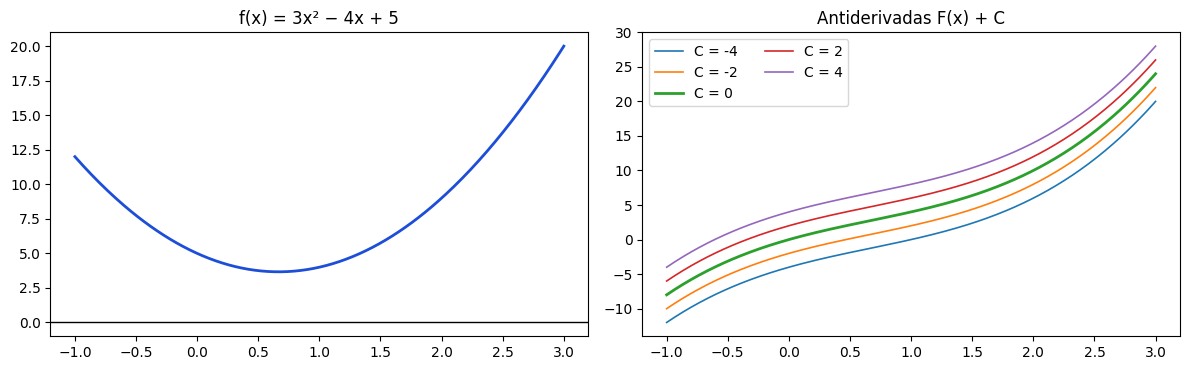

In [5]:
f_ej1 = sp.lambdify(x, ejemplos[0][1], "numpy")
F_ej1 = sp.lambdify(x, ejemplos[0][2], "numpy")

xs = np.linspace(-1, 3, 300)
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ejes[0].plot(xs, f_ej1(xs), color="#1d4ed8", lw=2); ejes[0].axhline(0, color="k", lw=1)
ejes[0].set_title("f(x) = 3x² − 4x + 5")
for C in range(-4, 5, 2):
    ejes[1].plot(xs, F_ej1(xs) + C, lw=2 if C == 0 else 1.2, label=f"C = {C}")
ejes[1].set_title("Antiderivadas F(x) + C"); ejes[1].legend(ncol=2)
plt.tight_layout(); plt.show()

## 6. Un error típico: una "antiderivada" incorrecta
Comprobamos qué detecta la verificación por derivación.

In [6]:
f = 1 / x
F_buena = sp.log(x) + 1                            # ✔ correcta: la constante +1 no importa
F_erronea = 1 / (2 * x**2)                              # ✘ error clásico: usar la regla de la potencia con n = -1

print("¿log(x) + 1 sirve para 1/x?   ", verificar(f, F_buena))
print("¿1/(2x²) sirve para 1/x?       ", verificar(f, F_erronea))
print("Su derivada real es:            ", sp.simplify(sp.diff(F_erronea, x)))

¿log(x) + 1 sirve para 1/x?    True
¿1/(2x²) sirve para 1/x?        False
Su derivada real es:             -1/x**3


## Preguntas para pensar

1. En la sección 6, ¿por qué la regla $\int x^n\,dx=\frac{x^{n+1}}{n+1}$ no puede aplicarse cuando $n=-1$? ¿Qué aparece en su lugar?
2. En la sección 3 SymPy puede escribir una antiderivada distinta de la tuya. ¿Cuál es la relación entre ambas? ¿Cómo lo comprueba el código?
3. **Ejercicio:** elige tres integrales de tu taller manual, escribe tu respuesta como expresión de SymPy y verifícala con `verificar(f, F)`. (Recuerda: el taller se resuelve a mano; este cuaderno solo sirve para **comprobar**.)